In [1]:
try:
     from dlroms import*
except:
     !pip install --no-deps git+https://github.com/NicolaRFranco/dlroms.git
     from dlroms import*
import numpy as np
import matplotlib.pyplot as plt
clc()

## Ex 1 - **Hailstone shield design** (Linear elasticity)

### FOM solver code

In [162]:
mesh = fe.unitsquaremesh(40, 40) # rescaling from [0cm,6cm]x[0cm,6cm] to [0,1]x[0,1]
Vh = fe.space(mesh, 'CG', 1, vector_valued = True)
Dh = fe.space(mesh, 'DG', 0)
clc()


In [163]:
from ufl_legacy import nabla_div
from scipy.sparse.linalg import spsolve
from scipy.sparse import csr_matrix
from fenics import Constant, DirichletBC, nabla_grad, Identity, TrialFunction, TestFunction, dot, dx, ds, inner, assemble


In [164]:
def Affine():
    """
    ═══════════════════════════════════════════════════════════════════
    OFFLINE STAGE — assemble all parameter-independent FEM operators.
    ═══════════════════════════════════════════════════════════════════

    GOAL: exploit the affine decomposition of A(μ) and F(μ):

        A(μ) = r · A1  +  1 · A2
        F(μ) = 1 · F1  +  m·sin(θ) · F2  +  (-m·cos(θ)) · F3

    where A1, A2, F1, F2, F3 are parameter-INDEPENDENT matrices/vectors
    assembled here ONCE, and r, m, θ are applied as cheap scalars online.

    PHYSICAL MEANING OF EACH OPERATOR:
    ┌─────┬──────────────────────────────────────────────────────────┐
    │ A1  │ stiffness of top layer Ω₁ (y>0.5),  λ=ν=r  →  soft     │
    │ A2  │ stiffness of bottom layer Ω₂ (y≤0.5), λ=ν=1 →  stiff   │
    │ F1  │ gravity — pulls every point in Ω downward               │
    │ F2  │ horizontal shape of hailstone impact on Γtop            │
    │ F3  │ vertical shape of hailstone impact on Γtop              │
    └─────┴──────────────────────────────────────────────────────────┘

    Returns: A1, A2, F1, F2, F3  (all FEniCS objects, shape Nh×Nh or Nh)
    """

    # ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
    # GEOMETRY OF THE IMPACT ZONE
    # ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
    x0    = 0.5   # center of impact: hailstone hits the middle of the top edge
    delta = 0.1   # half-width of impact zone = radius of hailstone (rescaled)
    tol   = 1e-5  # floating point tolerance — boundary DOFs at y=1.0 may be
                  # stored as 0.9999999 due to FP precision, so we use > 0.99

    # ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
    # TRIAL AND TEST FUNCTIONS
    # ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
    # u = trial function → the displacement field we are solving for
    # v = test function  → arbitrary vector field, used to derive weak form
    # Both live in Vh (vector-valued piecewise linear FEM space)
    u = TrialFunction(Vh)
    v = TestFunction(Vh)

    # ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
    # BODY FORCE: GRAVITY
    # ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
    # f = [0, -1]^T — uniform downward force acting on every point in Ω
    # This is fixed, does not depend on any parameter μ
    f = Constant((0, -1))

    # ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
    # STIFFNESS MATRIX A1 — TOP LAYER Ω₁ (y > 0.5)
    # ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
    # The top layer has λ=ν=r, but we factor out r and assemble with λ=ν=1.
    # Online we multiply by r: A_top(μ) = r · A1
    #
    # mask_1st = 1 where y > 0.5 (top layer), 0 elsewhere
    # We use DG0 (piecewise constant, discontinuous) because λ is
    # discontinuous across the interface y = 0.5
    mask_1st = fe.interpolate(lambda x: 1.0 * (x[1] > 0.5), Dh)

    # Weak form of linear elasticity on Ω₁ (with λ=ν=1, r applied online):
    #
    # a₁(u,v) = ∫_{Ω₁} [ (∇·u)(∇·v)              ← compression/volumetric term
    #                    + (∇u + ∇uᵀ) : ∇v ]  dΩ  ← shear/distortion term
    #
    # mask_1st restricts the integral to Ω₁ only (zeroes out Ω₂)
    a1_affine = mask_1st * (
          nabla_div(u) * nabla_div(v)                              # compression
        + inner(nabla_grad(u) + nabla_grad(u).T, nabla_grad(v))   # shear
    ) * dx                    # dx → volume integral over Ω
    A1 = assemble(a1_affine)  # assembled once, shape (Nh × Nh)

    # ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
    # STIFFNESS MATRIX A2 — BOTTOM LAYER Ω₂ (y ≤ 0.5)
    # ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
    # The bottom layer has λ=ν=1 always — no scalar multiplier needed online.
    # Online: A_bottom(μ) = 1 · A2  (coefficient is always 1)
    #
    # mask_2nd = 1 where y ≤ 0.5 (bottom layer), 0 elsewhere
    # Note: mask_1st + mask_2nd = 1 everywhere → they partition Ω exactly
    mask_2nd = fe.interpolate(lambda x: 1.0 * (x[1] <= 0.5), Dh)

    # Same bilinear form as A1 but restricted to Ω₂
    a2_affine = mask_2nd * (
          nabla_div(u) * nabla_div(v)                              # compression
        + inner(nabla_grad(u) + nabla_grad(u).T, nabla_grad(v))   # shear
    ) * dx                    # dx → volume integral over Ω
    A2 = assemble(a2_affine)  # assembled once, shape (Nh × Nh)

    # ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
    # LOAD VECTOR F1 — GRAVITY (BODY FORCE)
    # ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
    # F1 = ∫_Ω f · v dΩ   with f = [0, -1]^T
    #
    # - Uses dx → integrates over entire domain volume
    # - Parameter-independent: always enters F(μ) with coefficient 1
    # - Physically: weight of the shield itself pulling it down
    F1 = assemble(dot(f, v) * dx)   # shape (Nh,)

    # ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
    # IMPACT ZONE SHAPE FUNCTIONS
    # ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
    # The hailstone force is: g = [m·sin(θ), -m·cos(θ)]^T · 1_impact
    #
    # We split it into two direction-separated shapes:
    #   g = m·sin(θ) · T_shape_x  +  (-m·cos(θ)) · T_shape_y
    #
    # Both shapes are non-zero over IDENTICAL geometry (same impact zone),
    # but point in different directions:
    #   T_shape_x = [1, 0] in impact zone → unit horizontal force
    #   T_shape_y = [0, 1] in impact zone → unit vertical force
    #
    # Impact zone conditions (both must be true):
    #   (1) x[1] > 0.99           → DOF is on top edge Γtop (y ≈ 1)
    #                                using > 0.99 not == 1.0 to handle FP precision
    #   (2) |x[0] - x0| < δ + tol → DOF is within horizontal window [0.4, 0.6]

    # T_shape_x: [1, 0] inside impact zone, [0, 0] outside
    # → captures the horizontal (x) component of the impact
    T_shape_x = fe.interpolate(
        lambda x: [
            1.0 * (x[1] > 0.99) * (np.abs(x[0] - x0) < delta + tol),  # x = 1 in zone
            0.0                                                           # y = 0 always
        ], Vh
    )

    # T_shape_y: [0, 1] inside impact zone, [0, 0] outside
    # → captures the vertical (y) component of the impact
    T_shape_y = fe.interpolate(
        lambda x: [
            0.0,                                                           # x = 0 always
            1.0 * (x[1] > 0.99) * (np.abs(x[0] - x0) < delta + tol)   # y = 1 in zone
        ], Vh
    )

    # ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
    # LOAD VECTOR F2 — HORIZONTAL IMPACT SHAPE
    # ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
    # F2 = ∫_{∂Ω} T_shape_x · v ds

    F2 = assemble(dot(T_shape_x, v) * ds)   # shape (Nh,)

    # ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
    # LOAD VECTOR F3 — VERTICAL IMPACT SHAPE
    # ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
    # F3 = ∫_{∂Ω} T_shape_y · v ds
    F3 = assemble(dot(T_shape_y, v) * ds)   # shape (Nh,)

    return A1, A2, F1, F2, F3

In [165]:
A1 , A2 , F1 , F2 ,F3 = Affine()
clc()

In [166]:
def FOMsolver(mu, A1, A2, F1, F2, F3):

    tol = 1e-5
    def clamped_boundary(x, on_boundary):
        return on_boundary and x[1] < tol
    bc = DirichletBC(Vh, Constant((0, 0)), clamped_boundary)

    r, m, theta = mu

    # Step 1 — sum the full FEniCS matrix and vector
    A_mu = r * A1 + A2
    F_mu = F1 + m*np.sin(theta)*F2 + (-m*np.cos(theta))*F3

    # Step 2 — apply BCs to the full assembled system
    bc.apply(A_mu)
    bc.apply(F_mu)
    # Step 3 — convert to scipy and solve
    A_scipy = csr_matrix(A_mu.array())
    F_numpy = F_mu[:]

    return spsolve(A_scipy, F_numpy)

Text(0.5, 1.0, 'Warped domain')

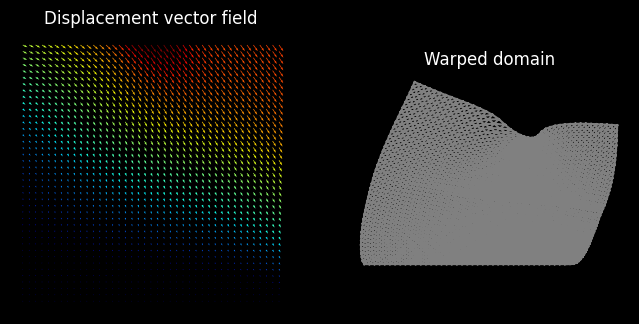

In [167]:
u = FOMsolver([0.75, 1, 0.4],A1 , A2 , F1 , F2 ,F3)

plt.figure(figsize = (8, 4))
plt.subplot(1, 2, 1)
fe.plot(u, Vh)
plt.title("Displacement vector field")
plt.subplot(1, 2, 2)
fe.plot(u, Vh, warp = True)
plt.title("Warped domain")


In [168]:
## task1
##1.1:
np.random.seed(0)
n_sim = 100
r_vals = np.random.uniform(0.5 , 1.0 , n_sim)
m_vals = np.random.uniform(0.5 , 2.0 , n_sim)
theta_vals = np.random.uniform(-0.4 , 0.4 , n_sim)
mu = np.column_stack((r_vals , m_vals , theta_vals))

In [169]:
ntrain = n_sim//2

In [170]:
## 1.2 creating the snapshots
Snapshots = []

for i in range(n_sim):
  snapshot = FOMsolver(mu[i] , A1 , A2 , F1 , F2 , F3)
  Snapshots.append(snapshot)
Snapshots = np.stack(Snapshots)

In [171]:
##1.3 SVD
from scipy.linalg import svd
X,S,YT = svd(Snapshots[:ntrain].T , full_matrices = False)


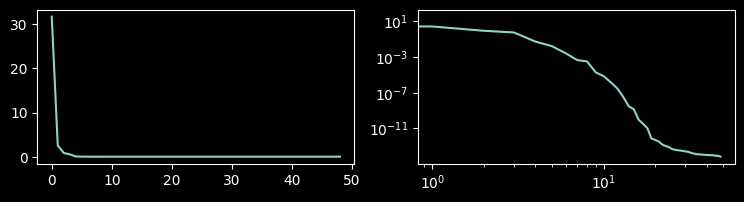

In [172]:
##plotting the SVD(start rom index 1)
plt.figure(figsize = (9,2))
plt.subplot(1,2,1)
plt.plot(S[1:])

plt.subplot(1,2,2)
plt.loglog(S[1:])
plt.show()

In [174]:
N = 10  ## number of basis functions
sused = S[:N]
captured = 0
total = 0
for i in range(len(sused)):
  captured += S[i]**2
for i in range(len(S)):
  total += S[i]**2
print(captured * 100 / total , "%")

99.99999999999243 %


In [175]:

V = X[: , :N]
V.shape

(3362, 10)

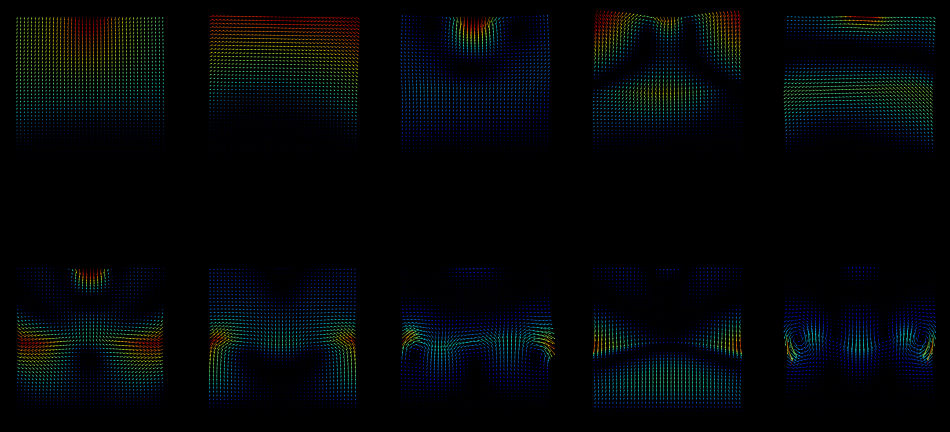

In [176]:
### mode shapes
plt.figure(figsize = (12,6))

for i in range(N):
  plt.subplot(2 , N//2 , i+1)
  fe.plot(V[ : , i] , Vh)

In [177]:
A1_sp = csr_matrix(A1.array())
A2_sp = csr_matrix(A2.array())
F1_np = F1[:]
F2_np = F2[:]
F3_np = F3[:]

In [178]:
##ROM stage
A1rb = V.T @ A1_sp @ V
A2rb = V.T @ A2_sp @ V

F1rb = V.T @ F1_np
F2rb = V.T @ F2_np
F3rb = V.T @ F3_np

def assembleROM(mu):
  r, m, theta = mu
  theta_A1 = r
  theta_A2 = 1.0

  theta_F1 = 1.0
  theta_F2 = m * np.sin(theta)
  theta_F3 = -1 * m * np.cos(theta)

# 3. Assemble the Reduced Matrix (Arb)
  Arb = (theta_A1 * A1rb) + (theta_A2 * A2rb)

  # 4. Assemble the Reduced Vector (Frb)
  Frb = (theta_F1 * F1rb) + (theta_F2 * F2rb) + (theta_F3 * F3rb)

  return Arb, Frb

In [179]:
def RBsolver(mu):
  Arb , frb = assembleROM(mu)
  c = np.linalg.solve(Arb , frb)
  URB = V@c
  return URB

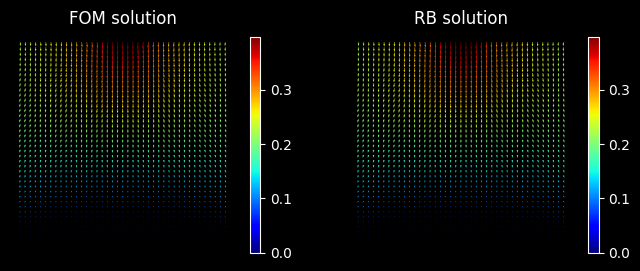

In [199]:
mu0 = np.array([0.75 , 1.0 , 0.0])
uFOM = FOMsolver(mu0 , A1 , A2 , F1 , F2 , F3)
uROM = RBsolver(mu0)

plt.figure(figsize = (8, 4))
plt.subplot(1, 2, 1)
fe.plot(uFOM, Vh, colorbar = True, shrink = 0.7)
plt.title("FOM solution")
plt.subplot(1, 2, 2)
fe.plot(uROM, Vh, colorbar = True, shrink = 0.7)
plt.title("RB solution")
plt.show()

In [191]:
# 2. Time complexity

from time import perf_counter
t0 = perf_counter()
FOMsolver(mu0 , A1 , A2 , F1 , F2 , F3)
t1 = perf_counter()
print("FOM evaluation time: %.2f milliseconds." % (1000*(t1-t0)))

t0 = perf_counter()
RBsolver(mu0)
t1 = perf_counter()
print("ROM evaluation time: %.2f milliseconds." % (1000*(t1-t0)))

FOM evaluation time: 148.98 milliseconds.
ROM evaluation time: 0.89 milliseconds.


In [192]:
RBtest = [RBsolver(m) for m in mu[ntrain:]]
RBtest = np.stack(RBtest).T

Utest = Snapshots[ntrain:].T
REs = np.linalg.norm(Utest-RBtest, axis = 0)/np.linalg.norm(Utest, axis = 0)
MRE = REs.mean()
print(f"Raw MRE value: {MRE}")

Raw MRE value: 4.742947907880425e-07


Third Task

In [193]:
m0 = 1.5
# Create a grid of collision angles from -0.4 to 0.4
theta_values = np.linspace(-0.4, 0.4, 100) ## devide into 100 steps
delta_critic = 0.5
r_star_list = []
theta_star_list = []

In [194]:
def max_vertical_def (r , theta):
    mu_task_3 = np.array([r , m0 , theta])
    u_RB_solver = RBsolver(mu_task_3)
    u_z = []
    for i in range(len(u_RB_solver)):
        if i % 2 != 0:
            u_z.append(u_RB_solver[i])
    return np.max(np.abs(u_z))


In [195]:
from scipy.optimize import bisect

In [196]:
# For each θ, we want the SMALLEST r ∈ [0.5, 1] such that:
#
#   max_{(x,y) ∈ Ω} |u^(y)_μ(x,y)| ≤ Δ_critic = 0.5
#
# This is a 1D root-finding problem: find r such that
#
#   residual(r) = max_vertical_def(r, θ) - Δ_critic = 0
for i in theta_values:
    def residual(r):
        return max_vertical_def(r , i) - delta_critic
    r_opt = bisect(residual , 0.5 , 1.0 , xtol = 1e-4)
    r_star_list.append(r_opt)

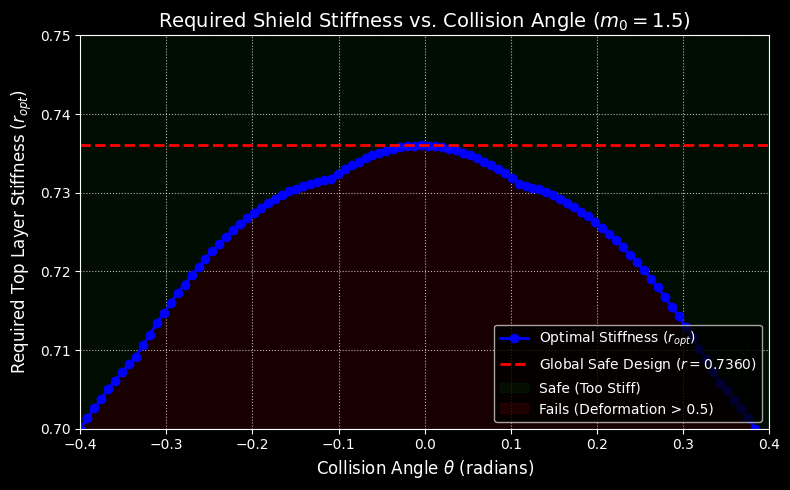

In [198]:
# 1. Create the plot figure
plt.figure(figsize=(8, 5))

# 2. Plot the main curve connecting all the computed r_opt values
plt.plot(theta_values, r_star_list, marker='o', linestyle='-', color='blue',
         linewidth=2, markersize=6, label="Optimal Stiffness ($r_{opt}$)")

# 3. Add a horizontal line representing the Global Safe Design
r_global = max(r_star_list)
plt.axhline(y=r_global, color='red', linestyle='--', linewidth=2,
            label=f"Global Safe Design ($r = {r_global:.4f}$)")

# 4. Fill the safe and unsafe regions for visual clarity
plt.fill_between(theta_values, r_star_list, 1.05, color='green', alpha=0.1, label="Safe (Too Stiff)")
plt.fill_between(theta_values, 0, r_star_list, color='red', alpha=0.1, label="Fails (Deformation > 0.5)")

# 5. Formatting the plot
plt.xlabel("Collision Angle $\\theta$ (radians)", fontsize=12)
plt.ylabel("Required Top Layer Stiffness ($r_{opt}$)", fontsize=12)
plt.title("Required Shield Stiffness vs. Collision Angle ($m_0 = 1.5$)", fontsize=14)

plt.xlim([min(theta_values), max(theta_values)])
plt.ylim([0.7, 0.75])
plt.grid(True, linestyle=':', alpha=0.7)
plt.legend(loc="lower right")

# 6. Render the plot
plt.tight_layout()
plt.show()

## Task 3 — Discussion

The plot shows how the minimum required stiffness $r^*(\theta)$ varies with the collision angle $\theta$.

**Key observations:**

- The worst case is $\theta = 0$ (vertical impact),  $m\cos(0) = m$, requiring the highest stiffness $r^*$.

- As $|\theta|$ increases, the vertical component of the impact force $m\cos\theta$
decreases, meaning the shield can be softer — hence $r^*(\theta)$ decreases away from $\theta = 0$.

- The curve is **symmetric around $\theta = 0$**, since $\cos\theta$ is an even function:
a hailstone hitting at angle $+\theta$ and one hitting at $-\theta$ produce the same
vertical deformation.

**Conclusion:** The company should choose:

$$r^* = r^*(\theta = 0) = \max_{\theta \in [-0.4, 0.4]} r^*(\theta)$$

This is the **global safe design** — the minimum stiffness that guarantees the vertical
deformation never exceeds $\Delta_{\text{critic}} = 0.5$, regardless of the collision angle.